# QCoDeS example with the Rigol DHO900 series oscilloscopes

The driver `RigolDHO900` controls the Rigol DHO914, DHO914S, DHO924 and DHO924S oscilloscopes (four channels, 12-bit ADC) over USB or LAN, including the 25 MHz function generator of the "S" models. The DHO800 series shares the programming guide; the driver connects to it as well, but has only been run on a DHO914S.

This notebook was run on a DHO914S with firmware 00.01.04. The generator output (GI) is connected to channel 1 through a 10:1 probe, so the examples measure the generator's own signals.

The firmware departs from the programming guide in several places (no `*OPC?` wait, silent clipping of out-of-range values, settings ignored under some conditions, keywords spelled differently). The driver works around them; the module docstring lists them.

## Connect

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from qcodes.instrument import Instrument

from qcodes_contrib_drivers.drivers.Rigol.Rigol_DHO900 import RigolDHO900

Instrument.close_all()
# the VISA address as listed by pyvisa, e.g. USB0::0x1AB1::0x044C::<serial>::INSTR
address = os.environ.get("DHO900_ADDRESS", "USB0::0x1AB1::0x044C::<serial>::INSTR")
scope = RigolDHO900("scope", address)
print(scope.n_channels, "channels; generator:", scope.has_awg)

Connected to: RIGOL TECHNOLOGIES DHO914S (serial:<serial>, firmware:00.01.04) in 0.19s
4 channels; generator: True


The driver writes nothing at connect and sends no device clear: on this firmware a USB device clear after a query that received no response leaves the USB interface unresponsive until the oscilloscope is power-cycled.

## Set up a channel, the generator and the trigger

Settings are grouped in submodules: `ch1` to `ch4` (also as `channels`), `timebase`, `acquisition`, `trigger`, `waveform`, `measurement`, `counter`, `dvm` and `awg`.

In [2]:
ch = scope.ch1
ch.enabled(True)
ch.probe_ratio(10)
ch.coupling("dc")
ch.scale(0.5)  # V/div
ch.offset(0.0)
for other in scope.channels[1:]:
    other.enabled(False)

awg = scope.awg
awg.function("sine")
awg.offset(0.0)
awg.amplitude(2.0)  # Vpp into a high impedance
awg.frequency(1e3)
awg.output(True)

scope.timebase.scale(200e-6)  # s/div, 10 divisions
scope.timebase.offset(0.0)
scope.trigger.type("edge")
scope.trigger.edge_source("ch1")
scope.trigger.edge_slope("rising")
scope.trigger.edge_level(0.0)
scope.trigger.sweep("auto")

Values outside the instrument's limits are refused before anything is sent; the instrument itself would clip them without an error. The limits depend on other settings, e.g. the offset range on the vertical scale and the probe ratio:

In [3]:
try:
    ch.offset(50.0)
except ValueError as error:
    print(error.args[0])

scope_ch1: offset 50.0 V is outside +-10 V at 0.5 V/div and probe ratio 10


## Acquire and read a waveform

`digitize()` starts a single acquisition and returns when it has stopped, so that all traces and measurements come from the same acquisition. In the `normal` waveform mode a trace contains the 1000 points on the display.

1000 points


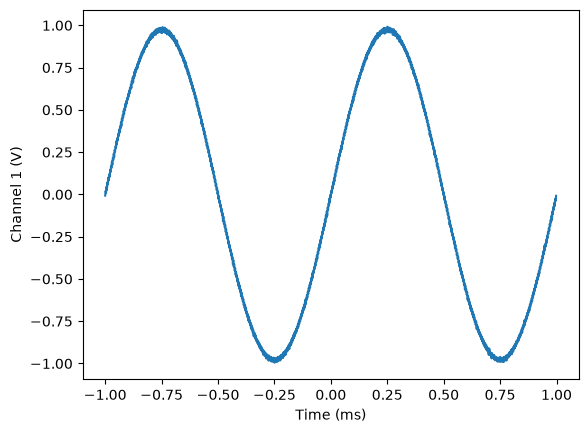

In [4]:
scope.waveform.mode("normal")
scope.digitize()
t = scope.waveform.time_axis()
y = ch.trace()
fig, ax = plt.subplots()
ax.plot(t * 1e3, y)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Channel 1 (V)")
print(len(y), "points")

In the `raw` mode a trace contains the whole memory of a stopped acquisition (the memory depth), read in chunks of `waveform.chunk_points`.

In [5]:
scope.acquisition.memory_depth(1e6)
scope.digitize()
scope.waveform.mode("raw")
y_raw = ch.trace()
t_raw = scope.waveform.time_axis()
print(f"{len(y_raw)} points at {scope.acquisition.sample_rate():.4g} Sa/s, "
      f"{t_raw[0] * 1e3:.2f} ms to {t_raw[-1] * 1e3:.2f} ms")
scope.waveform.mode("normal")

1000000 points at 3.125e+08 Sa/s, -1.60 ms to 1.60 ms


## Measurements

Each channel has parameters for the common automatic measurements; `measure()` makes any of the 42 measurement items (`MEASUREMENT_ITEMS`), including delays and phases between two channels. A measurement that cannot be made is NaN. Duty cycles, overshoot and preshoot are ratios.

In [6]:
scope.run()
print("Vpp", ch.vpp(), "V")
print("frequency", ch.frequency(), "Hz")
print("AC RMS", ch.ac_rms(), "V")
print("rise time", scope.measure("rise_time", "ch1"), "s")
print("duty cycle", ch.positive_duty())
print(scope.measure_statistics("vpp", "ch1"))

Vpp 1.9839 V
frequency 1000.7 Hz
AC RMS 0.69061 V
rise time 0.00028971 s


duty cycle

 0.50247
{'current': 1.9839, 'average': 1.9839, 'minimum': 1.9839, 'maximum': 1.9862, 'deviation': 0.0014648, 'count': 3.0}


## Measurements with the QCoDeS dataset

The generator amplitude swept against the measured peak-to-peak voltage:

Starting experimental run with id: 1. Using 'qcodes.dataset.do1d'


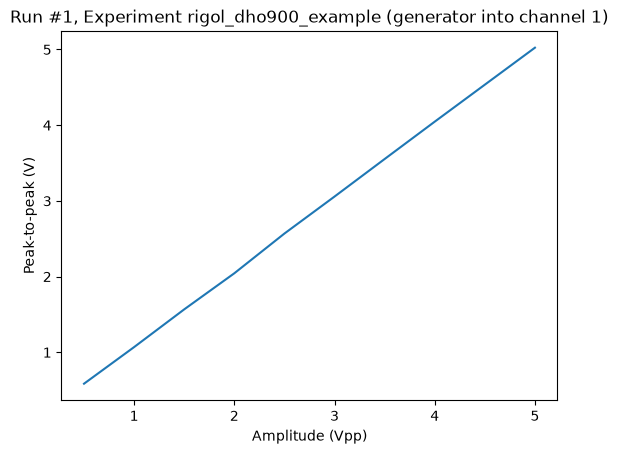

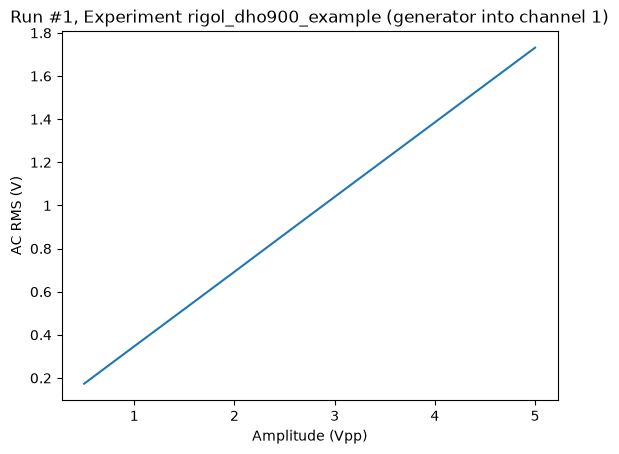

In [7]:
from qcodes.dataset import (
    do0d,
    do1d,
    initialise_or_create_database_at,
    load_or_create_experiment,
)

initialise_or_create_database_at("./rigol_dho900_example.db")
load_or_create_experiment("rigol_dho900_example", sample_name="generator into channel 1")
ch.scale(1.0)
dataset, _, _ = do1d(awg.amplitude, 0.5, 5.0, 10, 0.5, ch.vpp, ch.ac_rms, do_plot=True)

A trace is a `ParameterWithSetpoints`: `do0d` stores it with its time axis.

Starting experimental run with id: 2. Using 'qcodes.dataset.do0d'


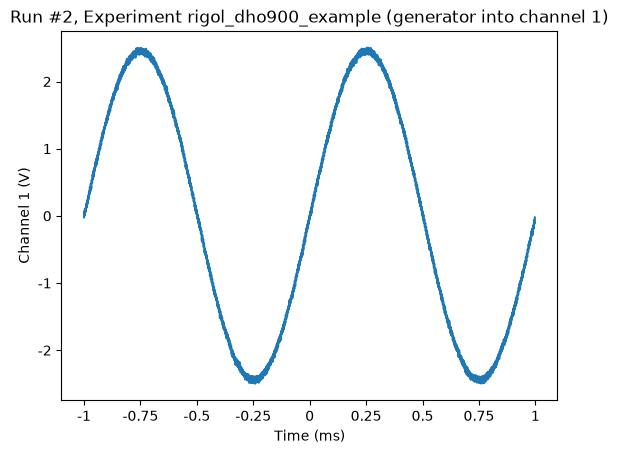

In [8]:
scope.digitize()
dataset, _, _ = do0d(ch.trace, do_plot=True)

## Frequency counter and voltmeter

In [9]:
import time

scope.run()
scope.counter.source("ch1")
scope.counter.mode("frequency")
scope.counter.enabled(True)
scope.dvm.source("ch1")
scope.dvm.mode("ac_rms")
scope.dvm.enabled(True)
# both read 0 until their first result: the voltmeter for about 2 s
deadline = time.monotonic() + 10
while time.monotonic() < deadline and (
    scope.counter.value() == 0 or abs(scope.dvm.value()) < 0.01
):
    time.sleep(0.5)
time.sleep(0.5)
print("counter", scope.counter.value(), "Hz")
print("voltmeter", scope.dvm.value(), "V")
scope.counter.enabled(False)
scope.dvm.enabled(False)

counter 1000.0 Hz
voltmeter 1.730802 V


The counter counts only while the acquisition runs; the voltmeter measures in either state.

## Close

In [10]:
awg.output(False)
scope.close()